# FlowCast exploratory data analysis

This notebook examines only the supplied Northline Corridor observations. Repaired sensor values are excluded from the descriptive calculations. The plots and tables explain the modelling choices.

In [1]:
from pathlib import Path
import sys
root = Path.cwd()
if root.name == 'notebooks':
    root = root.parent
sys.path.insert(0, str(root))
import pandas as pd
from IPython.display import display, Image
from src.features import load_dataset
from src.utils import ROOT
df = load_dataset()
print(f'{len(df):,} grid rows across {df.road_id.nunique()} roads')
print(df.timestamp.min(), 'to', df.timestamp.max())


181,200 grid rows across 25 roads
2025-01-01 00:00:00+05:30 to 2025-05-31 23:30:00+05:30


,count,mean,std,min,25%,50%,75%,max,median,mode,variance
traffic_volume,172114.0,431.290,283.407,41.0,195.0,362.00,601.00,2090.00,362.00,158.00,80319.337
avg_speed,172122.0,42.110,11.393,6.7,36.2,44.90,50.90,64.80,44.90,50.90,129.795
occupancy,172128.0,31.163,19.618,3.0,14.2,27.00,43.70,100.00,27.00,12.60,384.864
travel_time,176701.0,3.566,2.529,0.8,2.2,3.12,4.09,29.91,3.12,3.21,6.394
rainfall,176701.0,0.192,1.059,0.0,0.0,0.00,0.00,8.90,0.00,0.00,1.121
visibility,176701.0,9674.871,1498.127,301.0,10000.0,10000.00,10000.00,10000.00,10000.00,10000.00,2244383.832
temperature,176701.0,17.972,4.372,5.8,14.6,18.00,21.30,29.80,18.00,17.70,19.111
road_capacity,176701.0,1882.054,326.675,1259.0,1670.0,1888.00,2184.00,2327.00,1888.00,1348.00,106716.774


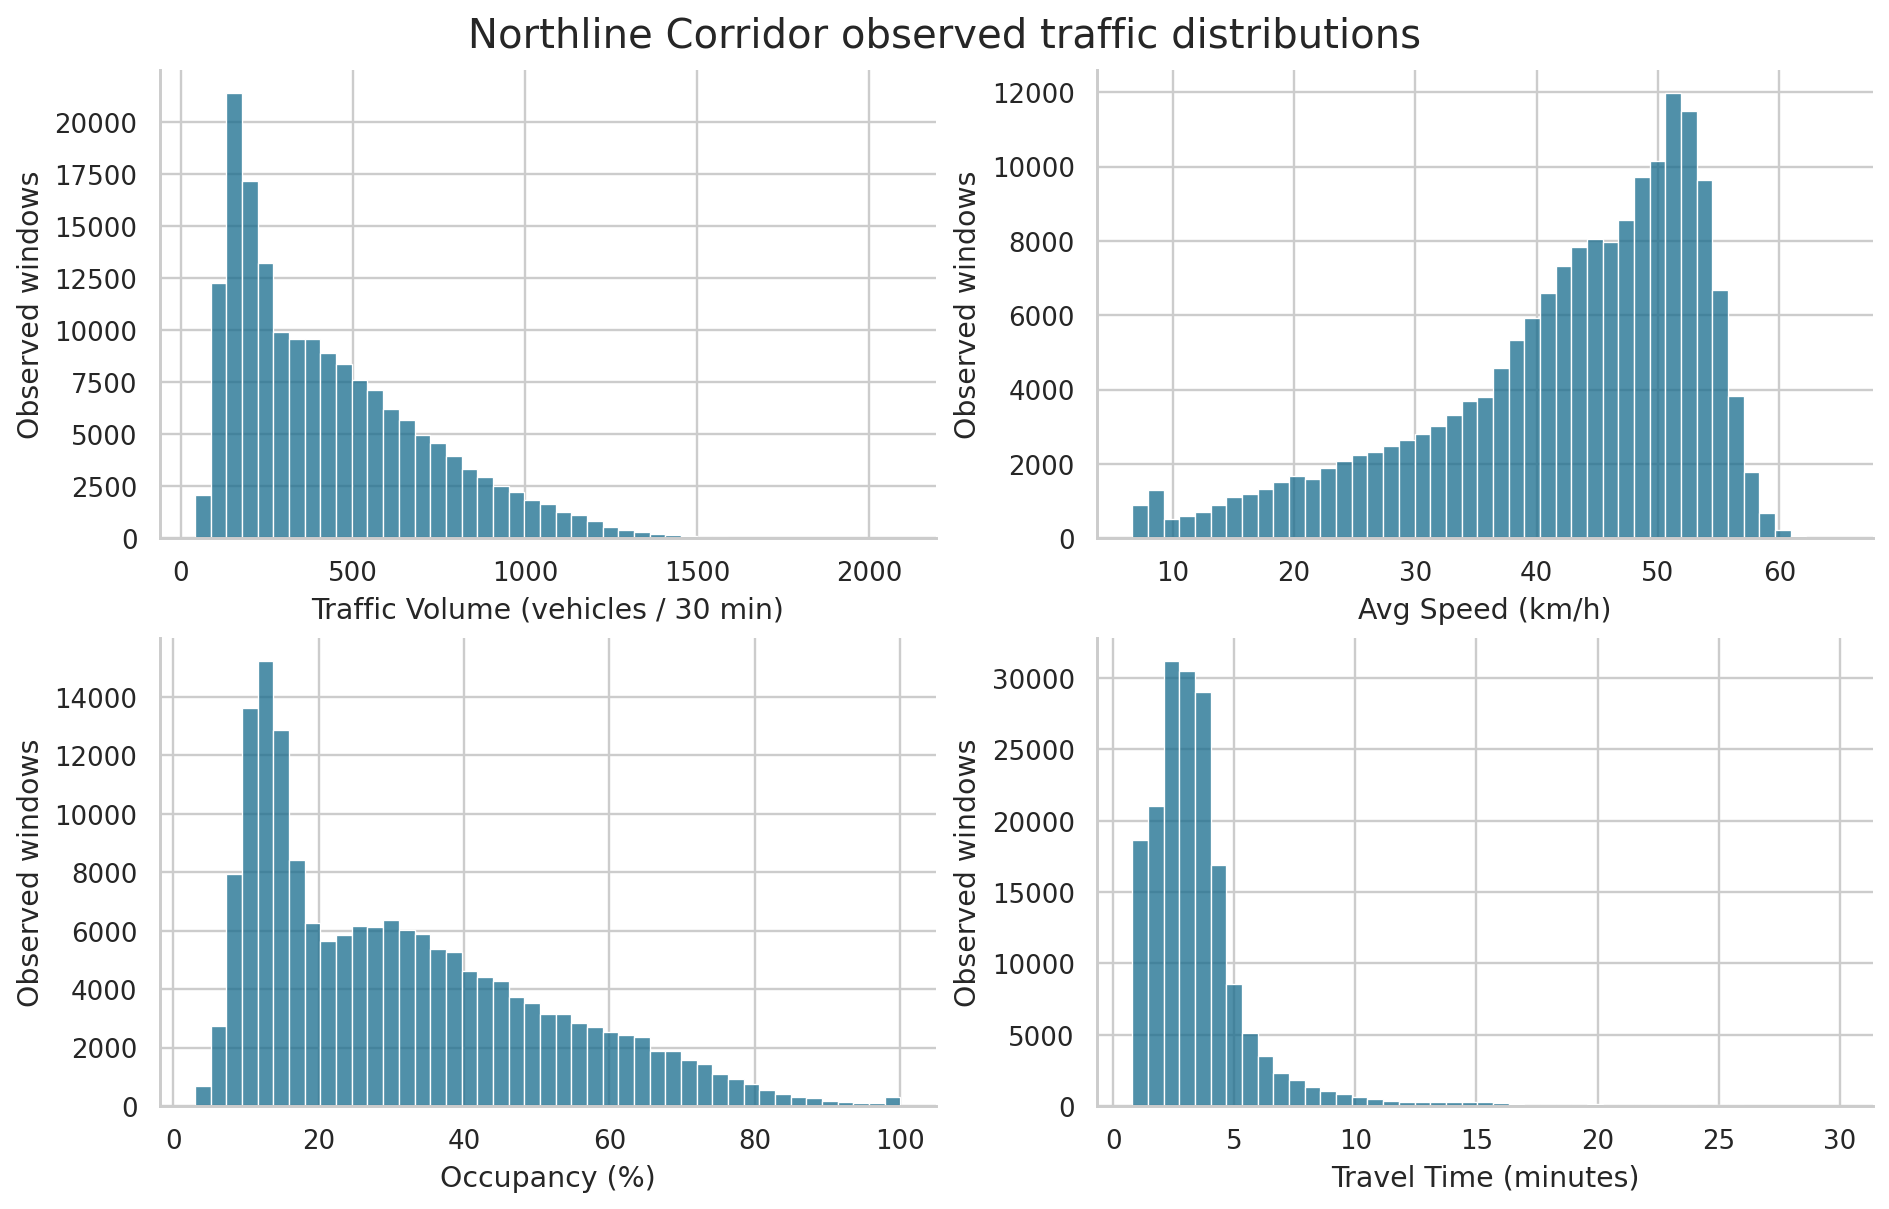

In [2]:
display(pd.read_csv(ROOT / 'reports/descriptive_statistics.csv', index_col=0).round(3))
display(Image(filename=str(ROOT / 'reports/figures/eda_distributions.png')))

## Correlation and covariance

Traffic volume, speed, occupancy and travel time share information. We compare a scaled linear baseline with trees that can learn non-linear relationships. Correlation describes association, not cause.

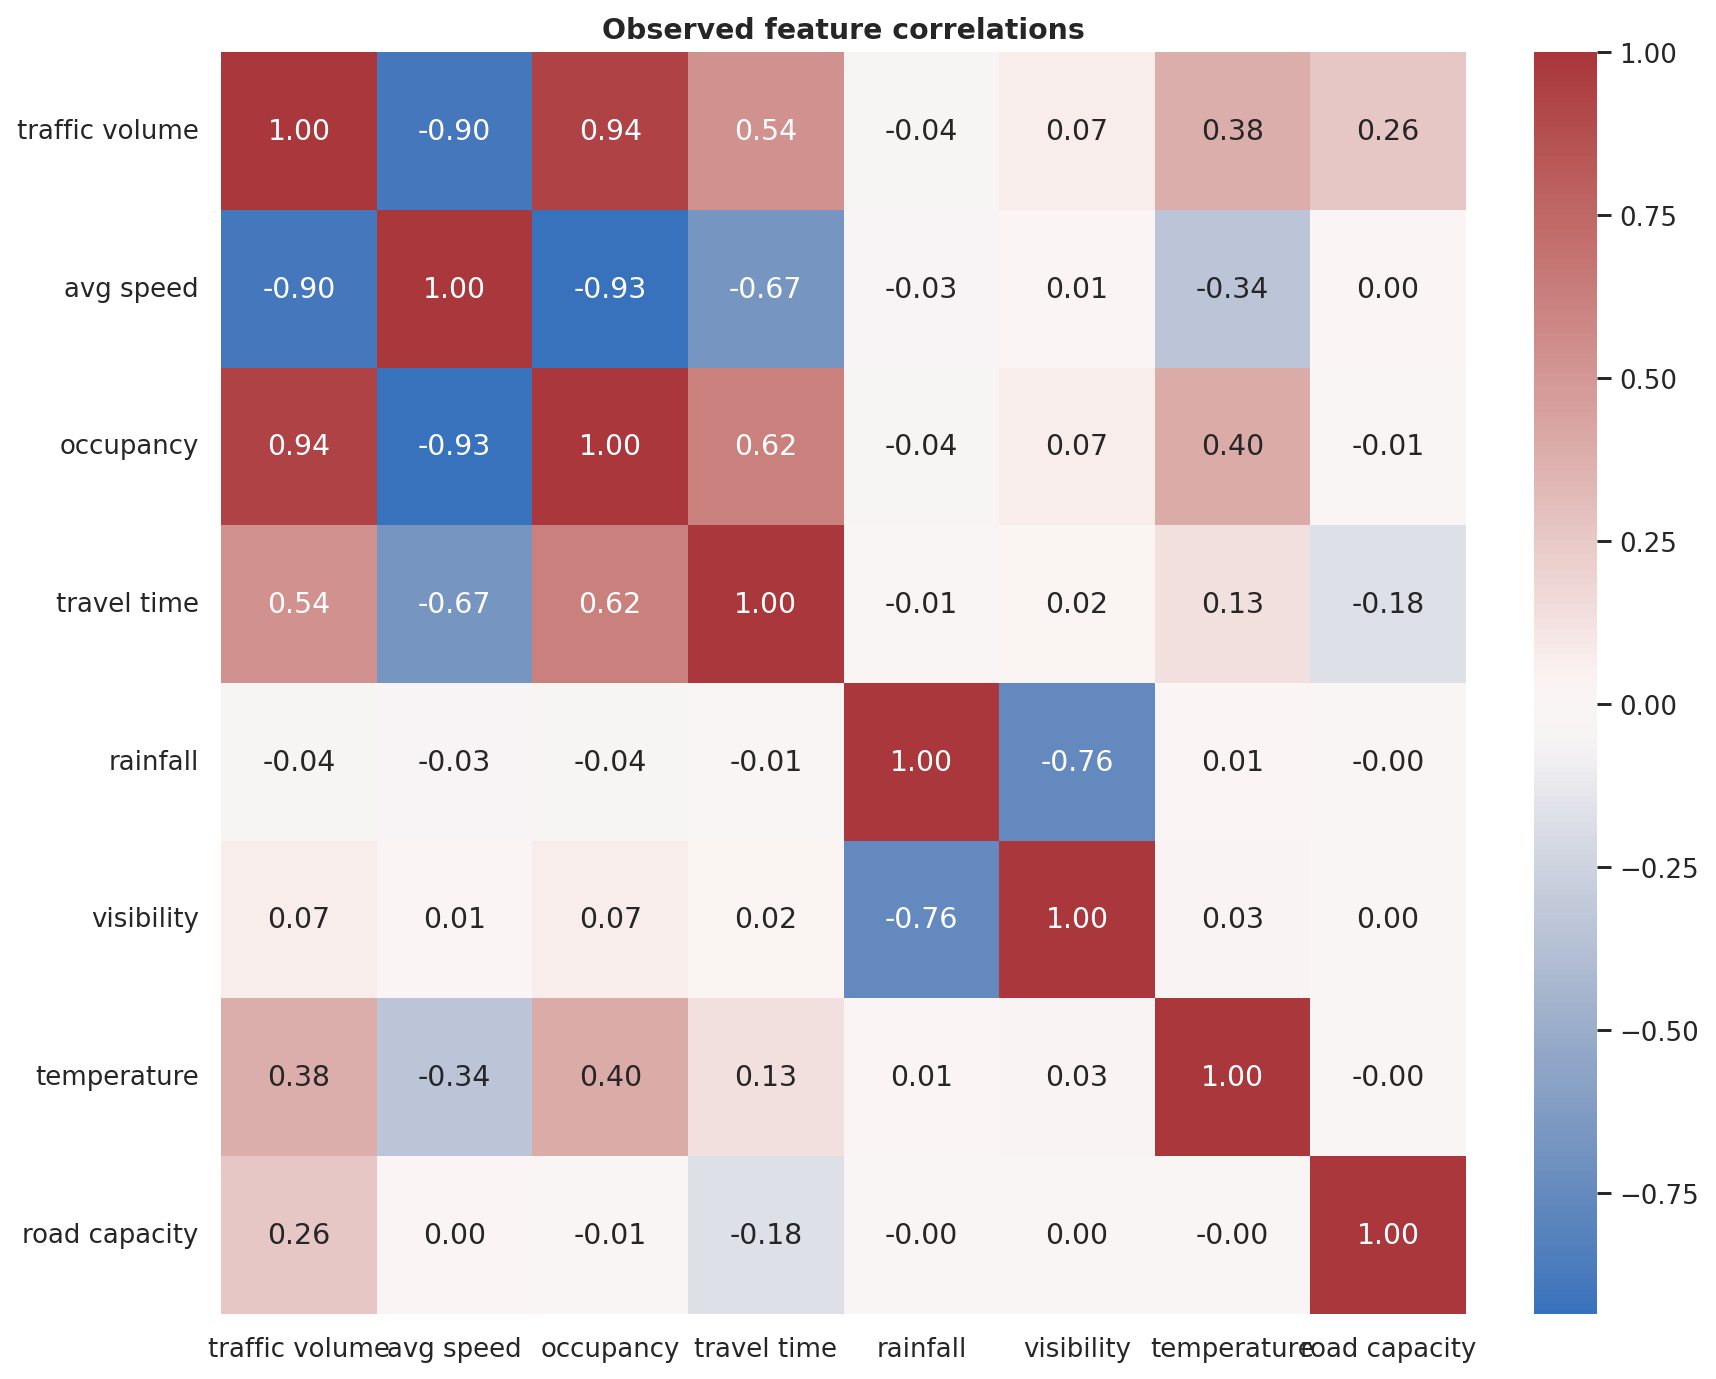

,traffic_volume,avg_speed,occupancy,travel_time,rainfall,visibility,temperature,road_capacity
traffic_volume,80319.34,-2893.91,5215.50,384.19,-11.44,30850.03,476.77,24531.44
avg_speed,-2893.91,129.80,-208.82,-19.38,-0.39,251.92,-16.92,16.66
occupancy,5215.50,-208.82,384.86,30.80,-0.78,2156.74,34.49,-32.06
travel_time,384.19,-19.38,30.80,6.39,-0.02,79.02,1.46,-145.79
rainfall,-11.44,-0.39,-0.78,-0.02,1.12,-1202.70,0.05,-0.45
visibility,30850.03,251.92,2156.74,79.02,-1202.70,2244383.83,211.28,1209.17
temperature,476.77,-16.92,34.49,1.46,0.05,211.28,19.11,-0.67
road_capacity,24531.44,16.66,-32.06,-145.79,-0.45,1209.17,-0.67,106716.77


In [3]:
display(Image(filename=str(ROOT / 'reports/figures/eda_correlations.png')))
display(pd.read_csv(ROOT / 'reports/covariance.csv', index_col=0).round(2))

## Time patterns and weather

Daily peaks motivate cyclical time encodings, yesterday's same-window lag and recent rolling summaries. Weather is observed hourly. Forecasts use only the origin-time weather. Rare weather groups have fewer observations, so group comparisons need care.

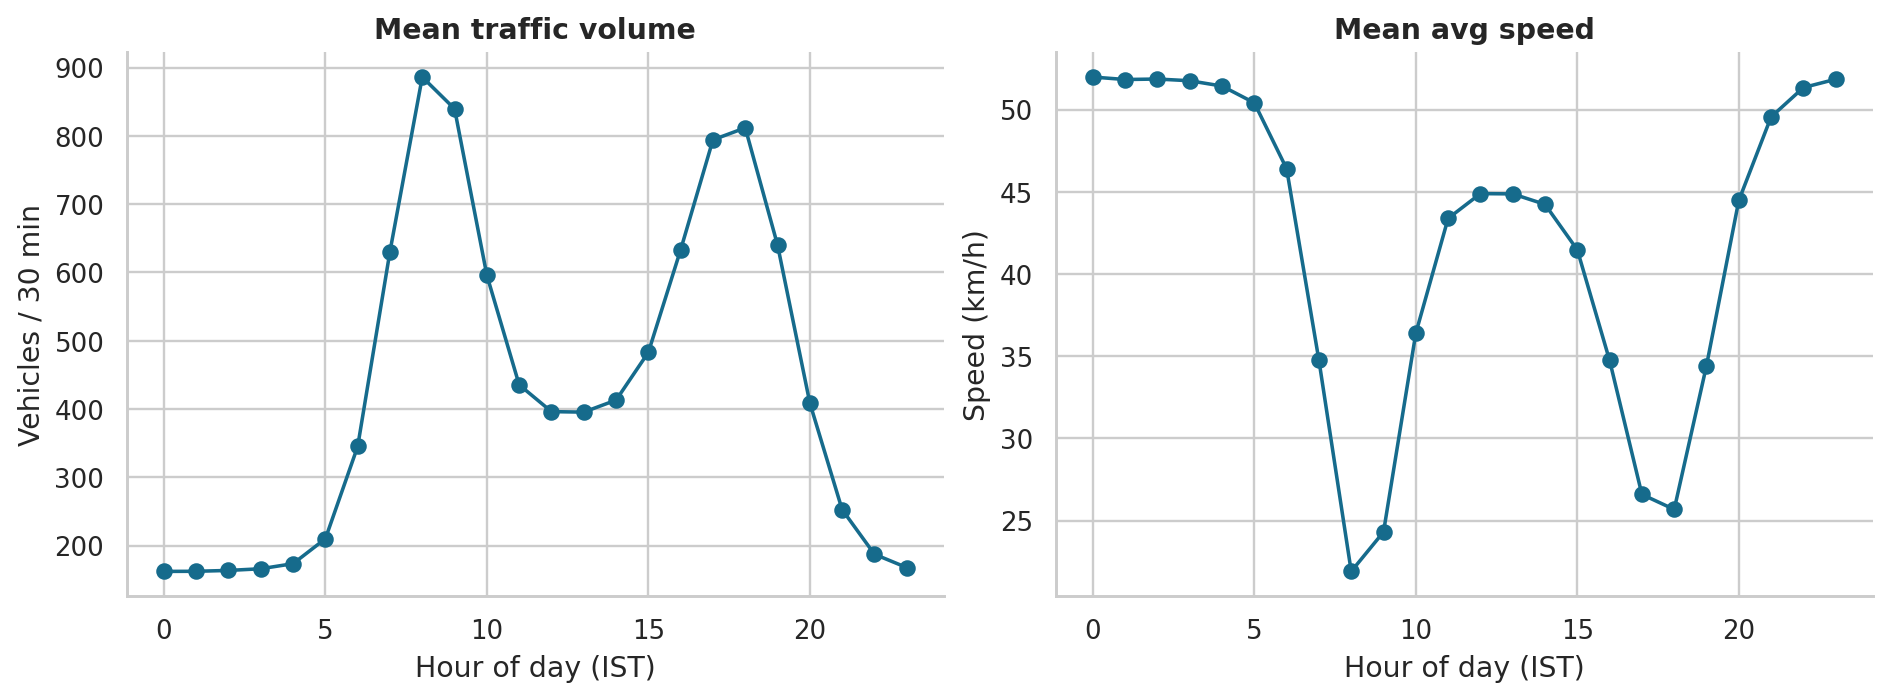

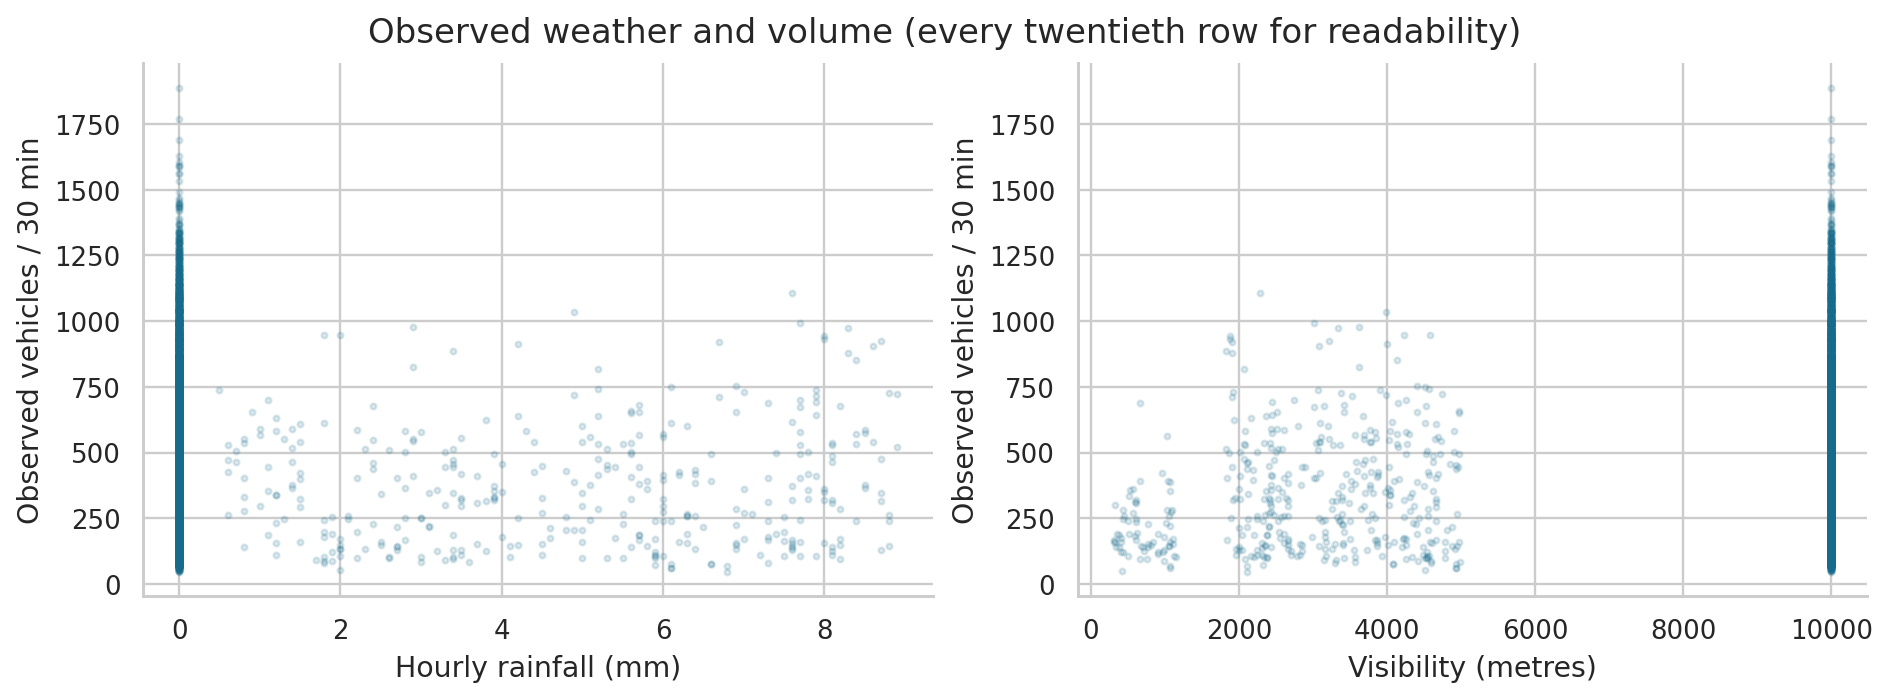

,count,mean,std
weather_condition,,,
Clear,129292,437.27,287.32
Cloudy,34833,428.89,278.31
Fog,1215,217.88,127.04
Rain,6774,367.83,226.00


In [4]:
display(Image(filename=str(ROOT / 'reports/figures/peak_hour_patterns.png')))
display(Image(filename=str(ROOT / 'reports/figures/weather_observations.png')))
display(df.loc[df.traffic_volume_observed].groupby('weather_condition').traffic_volume.agg(['count', 'mean', 'std']).round(2))

## Modelling decisions

Use chronological validation because future traffic is the prediction task. Retain physically valid traffic peaks instead of clipping all statistical extremes. Keep causal imputations separate from historical interpolation. Include road capacity, lagged flow and weather features, then compare their value in the model results. See the modelling notebook for the measured benchmark.